# Phase 1 · ML Fundamentals · Day 1
## Foundations of ML & Math Essentials

**Goal:** Fetch/load the crop-yield dataset, inspect it, shuffle 200 farm-season rows (when available), split 80/20 in pure NumPy, and calculate mean, variance, and standard deviation of training yield.

**Dataset:** [Kaggle – Crop Yield Prediction](https://www.kaggle.com/datasets/patelris/crop-yield-prediction-dataset)

> The Kaggle dataset's columns may not exactly match the course example (rainfall, fertiliser, year). This notebook inspects the available columns and uses rainfall/year as features when present. It does not fabricate a fertiliser column. If you have a different course-provided CSV with fertiliser, add that feature after inspecting columns.

**Time-split caution:** Random shuffling is what this exercise asks for. If your goal is to predict future seasons, use a chronological split by year instead to avoid leakage across seasons.


### 1. Import libraries
NumPy is used for array operations and the train-test split. Pandas is used only to read and inspect the CSV.

In [1]:
import numpy as np
import pandas as pd

### 2. Get the dataset
Download the CSV from Kaggle to your computer (sign-in may be required), then upload it using the cell below. Select the crop-yield CSV file, often named `yield_df.csv`.

In [2]:
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("File:", filename)
print("Shape:", df.shape)
display(df.head())

Saving yield_df.csv to yield_df.csv
File: yield_df.csv
Shape: (28242, 8)


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


### 3. Inspect columns and data quality
Review the column names and missing-value counts before selecting variables. Dataset schemas can differ, so do not assume a column exists.

In [3]:
print("Columns:")
print(df.columns.tolist())

print("Missing values per column:")
print(df.isna().sum())

print("Data types:")
print(df.dtypes)

Columns:
['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
Missing values per column:
Unnamed: 0                       0
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64
Data types:
Unnamed: 0                         int64
Area                              object
Item                              object
Year                               int64
hg/ha_yield                        int64
average_rain_fall_mm_per_year    float64
pesticides_tonnes                float64
avg_temp                         float64
dtype: object


### 4. Select features and target
This Kaggle version commonly includes rainfall, year, and yield columns. The code below finds them using likely column-name patterns and stops with a helpful message if it cannot identify yield/rainfall. It uses rainfall and year as features when year is present. Fertiliser is not assumed to be present.

In [4]:
# Match columns by common names (case-insensitive)
columns_lower = {str(c).strip().lower(): c for c in df.columns}

def find_column(candidates):
    for candidate in candidates:
        if candidate.lower() in columns_lower:
            return columns_lower[candidate.lower()]
    return None

rainfall_col = find_column([
    "average_rain_fall_mm_per_year", "rainfall", "rainfall_mm", "rain"
])
yield_col = find_column(["hg/ha_yield", "yield", "crop_yield", "yield_t_ha"])
year_col = find_column(["year", "season_year"])
fertiliser_col = find_column(["fertiliser", "fertilizer", "fertiliser_kg", "fertilizer_kg"])

print("Rainfall column:", rainfall_col)
print("Yield column:", yield_col)
print("Year column:", year_col)
print("Fertiliser column (if any):", fertiliser_col)

if rainfall_col is None or yield_col is None:
    raise ValueError("Could not identify rainfall and yield columns. Inspect df.columns above and edit the column selections manually.")

feature_cols = [rainfall_col]
if fertiliser_col is not None:
    feature_cols.append(fertiliser_col)
if year_col is not None:
    feature_cols.append(year_col)

data = df[feature_cols + [yield_col]].copy()
# Convert selected columns to numeric; non-numeric entries become missing
for col in feature_cols + [yield_col]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data = data.dropna().reset_index(drop=True)

print("Selected features:", feature_cols)
print("Target:", yield_col)
print("Clean rows:", len(data))
display(data.head())

Rainfall column: average_rain_fall_mm_per_year
Yield column: hg/ha_yield
Year column: Year
Fertiliser column (if any): None
Selected features: ['average_rain_fall_mm_per_year', 'Year']
Target: hg/ha_yield
Clean rows: 28242


,average_rain_fall_mm_per_year,Year,hg/ha_yield
0,1485.0,1990,36613
1,1485.0,1990,66667
2,1485.0,1990,23333
3,1485.0,1990,12500
4,1485.0,1990,7000


### 5. Use up to 200 rows
The course exercise asks for 200 farm-season rows. We take a reproducible sample of 200 if at least 200 clean rows are available; otherwise we use all remaining clean rows and report that count.

In [6]:
n_rows = min(200, len(data))
data_200 = data.sample(n=n_rows, random_state=0).reset_index(drop=True)
print("Rows selected:", len(data_200))
if len(data_200) < 200:
    print("Note: fewer than 200 clean rows were available, so all clean rows were used.")

Rows selected: 200


### 6. Make NumPy arrays: X (features) and y (yield label)

In [7]:
X = data_200[feature_cols].to_numpy(dtype=float)
y = data_200[yield_col].to_numpy(dtype=float)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of features:", X.shape[1])
print("Number of observations:", len(y))

X shape: (200, 2)
y shape: (200,)
Number of features: 2
Number of observations: 200


### 7. Shuffle and split 80/20 using pure NumPy
Use a seeded NumPy random generator so the split can be reproduced. The same indices are applied to X and y to keep each feature row matched to its yield label.

In [8]:
rng = np.random.default_rng(0)
idx = rng.permutation(len(X))
cut = int(0.8 * len(X))
tr, te = idx[:cut], idx[cut:]

X_train, X_test = X[tr], X[te]
y_train, y_test = y[tr], y[te]

print("Train rows:", len(tr))
print("Test rows:", len(te))
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Sanity check: indices do not overlap
print("Train/test overlap:", len(set(tr).intersection(set(te))))

Train rows: 160
Test rows: 40
X_train shape: (160, 2)
X_test shape: (40, 2)
y_train shape: (160,)
y_test shape: (40,)
Train/test overlap: 0


### 8. Compute training-yield mean, variance, and standard deviation
NumPy uses population variance/std by default (`ddof=0`). These values describe the training subset. The yield unit is whatever unit the dataset target column uses; preserve it in your report.

In [9]:
mean_yield = y_train.mean()
variance_yield = y_train.var()
std_yield = y_train.std()

print(f"Training mean yield: {mean_yield:.4f}")
print(f"Training variance: {variance_yield:.4f}")
print(f"Training standard deviation: {std_yield:.4f}")
print(f"Mean yield ± standard deviation: {mean_yield:.2f} ± {std_yield:.2f}")

Training mean yield: 78410.1000
Training variance: 7509099822.9150
Training standard deviation: 86655.0623
Mean yield ± standard deviation: 78410.10 ± 86655.06


### 9. Optional: plot yield distribution
A histogram helps visualize the distribution and spread of crop yields. This is optional for the Day 1 requirement.

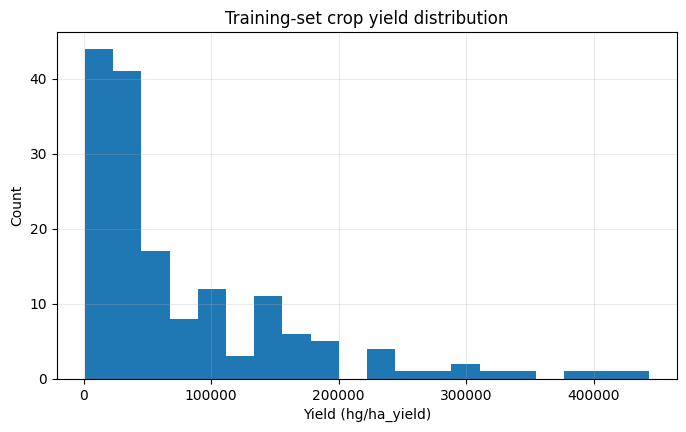

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4.5))
plt.hist(y_train, bins=20)
plt.xlabel(f"Yield ({yield_col})")
plt.ylabel("Count")
plt.title("Training-set crop yield distribution")
plt.grid(alpha=0.25)
plt.show()

### 10. Day 1 results summary
Run this cell to produce a compact summary you can paste into your report. Confirm the units based on the dataset documentation.

In [11]:
print("DAY 1 SUMMARY")
print("-------------")
print(f"Clean dataset rows available: {len(data)}")
print(f"Rows selected: {len(data_200)}")
print(f"Training rows: {len(y_train)} ({len(y_train)/len(y):.0%})")
print(f"Testing rows: {len(y_test)} ({len(y_test)/len(y):.0%})")
print(f"Features used: {feature_cols}")
print(f"Target: {yield_col}")
print(f"Training mean yield: {mean_yield:.4f}")
print(f"Training variance: {variance_yield:.4f}")
print(f"Training standard deviation: {std_yield:.4f}")
print(f"Mean ± std: {mean_yield:.2f} ± {std_yield:.2f}")

DAY 1 SUMMARY
-------------
Clean dataset rows available: 28242
Rows selected: 200
Training rows: 160 (80%)
Testing rows: 40 (20%)
Features used: ['average_rain_fall_mm_per_year', 'Year']
Target: hg/ha_yield
Training mean yield: 78410.1000
Training variance: 7509099822.9150
Training standard deviation: 86655.0623
Mean ± std: 78410.10 ± 86655.06
